In [1]:
!pip -q install kaggle scikit-learn seaborn

In [2]:
from google.colab import files
from pathlib import Path
import zipfile
import os

print("Faça o upload do seu arquivo kaggle.json:")
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d pavansanagapati/images-dataset

DATA_DIR = Path("/content/dataset")
DATA_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = Path("/content/images-dataset.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Extração concluída!")
print(f"Diretório do dataset: {DATA_DIR}")
print(f"Total de arquivos extraídos: {sum(1 for p in DATA_DIR.rglob('*') if p.is_file())}")

Faça o upload do seu arquivo kaggle.json:


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/pavansanagapati/images-dataset
License(s): CC0-1.0
100% 1.01G/1.01G [01:00<00:00, 18.0MB/s]

Extração concluída!
Diretório do dataset: /content/dataset
Total de arquivos extraídos: 3606


In [3]:
from collections import Counter

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"
}

all_images = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print(f"Total de imagens encontradas: {len(all_images)}")

for folder in sorted(p for p in DATA_DIR.rglob("*") if p.is_dir()):
    images_here = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    if images_here:
        print(f"{folder}: {images_here} imagens")

print("\nExemplos de arquivos:")
for path in all_images[:15]:
    print(path)

Total de imagens encontradas: 3606
/content/dataset/data/bike: 365 imagens
/content/dataset/data/cars: 420 imagens
/content/dataset/data/cats: 202 imagens
/content/dataset/data/data/bike: 365 imagens
/content/dataset/data/data/cars: 420 imagens
/content/dataset/data/data/cats: 202 imagens
/content/dataset/data/data/dogs: 202 imagens
/content/dataset/data/data/flowers: 210 imagens
/content/dataset/data/data/horses: 202 imagens
/content/dataset/data/data/human: 202 imagens
/content/dataset/data/dogs: 202 imagens
/content/dataset/data/flowers: 210 imagens
/content/dataset/data/horses: 202 imagens
/content/dataset/data/human: 202 imagens

Exemplos de arquivos:
/content/dataset/data/dogs/dog.114.jpg
/content/dataset/data/dogs/dog.1.jpg
/content/dataset/data/dogs/dog.19.jpg
/content/dataset/data/dogs/dog.196.jpg
/content/dataset/data/dogs/dog.200.jpg
/content/dataset/data/dogs/dog.83.jpg
/content/dataset/data/dogs/dog.38.jpg
/content/dataset/data/dogs/dog.97.jpg
/content/dataset/data/dogs/do

In [4]:
import random
import numpy as np
import torch

from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision import datasets
from torchvision.models import ResNet50_Weights
from sklearn.model_selection import train_test_split

SEED = 12
BATCH_SIZE = 16
EPOCHS = 10
LEARNING_RATE = 1e-3
IMAGE_SIZE = 224

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Dispositivo:", device)

# Ajusta o caminho para a pasta interna que não contém a pasta redundante 'data'
dataset_root = DATA_DIR / "data" / "data"

if not dataset_root.exists():
    raise RuntimeError(
        f"Diretório do dataset não encontrado: {dataset_root}"
    )

print("Pasta selecionada:", dataset_root)

# Pré-processamento compatível com os pesos ImageNet.
weights = ResNet50_Weights.DEFAULT
preprocess = weights.transforms()

dataset = datasets.ImageFolder(
    root=str(dataset_root),
    transform=preprocess
)

class_names = dataset.classes
targets = np.array(dataset.targets)
indices = np.arange(len(dataset))

print("Classes:", class_names)
print("Quantidade de classes:", len(class_names))
print("Total de imagens válidas:", len(dataset))

# Valida a estrutura das classes esperadas.
expected_classes = {
    "bike",
    "cars",
    "cats",
    "dogs",
    "flowers",
    "horses",
    "human"
}

if set(class_names) != expected_classes:
    raise RuntimeError(
        "A estrutura das classes está incorreta.\n"
        f"Classes encontradas: {class_names}\n"
        f"Classes esperadas: {sorted(expected_classes)}\n"
        "Verifique o caminho dataset_root."
    )

for name, count in zip(
    class_names,
    np.bincount(targets, minlength=len(class_names))
):
    print(f"{name}: {count} imagens")

# 70% treino, 15% validação e 15% teste.
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=targets
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=targets[temp_idx]
)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

# DataLoaders.
# num_workers=0 evita problemas com subprocessos no Colab.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(f"\nTreino: {len(train_dataset)} imagens")
print(f"Validação: {len(val_dataset)} imagens")
print(f"Teste: {len(test_dataset)} imagens")

Dispositivo: cuda
Pasta selecionada: /content/dataset/data/data
Classes: ['bike', 'cars', 'cats', 'dogs', 'flowers', 'horses', 'human']
Quantidade de classes: 7
Total de imagens válidas: 1803
bike: 365 imagens
cars: 420 imagens
cats: 202 imagens
dogs: 202 imagens
flowers: 210 imagens
horses: 202 imagens
human: 202 imagens

Treino: 1262 imagens
Validação: 270 imagens
Teste: 271 imagens


In [5]:
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet50

model = resnet50(weights=weights)

# Congela todos os parâmetros pré-treinados.
for param in model.parameters():
    param.requires_grad = False

# Substitui o classification head.
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(class_names))

# A nova camada é treinável.
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=LEARNING_RATE
)

print("Classes:", len(class_names))
print("Parâmetros treináveis:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))
print("Parâmetros totais:",
      sum(p.numel() for p in model.parameters()))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 184MB/s]


Classes: 7
Parâmetros treináveis: 14343
Parâmetros totais: 23522375


In [6]:
import copy
from tqdm.auto import tqdm

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_model_state = None

for epoch in range(EPOCHS):
    # Backbone congelado em modo eval; somente o head treina.
    model.eval()
    model.fc.train()

    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in tqdm(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        running_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = running_correct / total

    # Avaliação no conjunto de validação.
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Época {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

# Recupera a versão com menor loss de validação.
model.load_state_dict(best_model_state)
model.eval()

  0%|          | 0/79 [00:00<?, ?it/s]

Época 01/10 | Train Loss: 0.5599 | Val Loss: 0.1475 | Train Acc: 0.9200 | Val Acc: 1.0000


  0%|          | 0/79 [00:00<?, ?it/s]

Época 02/10 | Train Loss: 0.1044 | Val Loss: 0.0741 | Train Acc: 0.9929 | Val Acc: 1.0000


  0%|          | 0/79 [00:00<?, ?it/s]

...

  0%|          | 0/79 [00:00<?, ?it/s]

Época 09/10 | Train Loss: 0.0107 | Val Loss: 0.0174 | Train Acc: 1.0000 | Val Acc: 1.0000


  0%|          | 0/79 [00:00<?, ?it/s]

Época 10/10 | Train Loss: 0.0090 | Val Loss: 0.0158 | Train Acc: 1.0000 | Val Acc: 1.0000


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

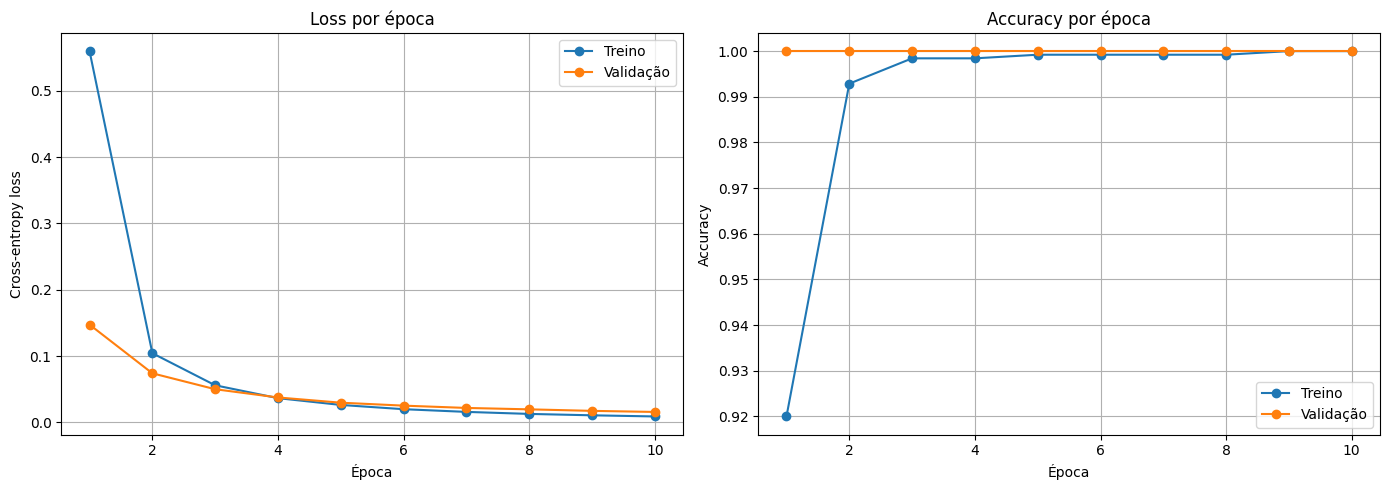

In [7]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    epochs_range, history["train_loss"],
    marker="o", label="Treino"
)
axes[0].plot(
    epochs_range, history["val_loss"],
    marker="o", label="Validação"
)
axes[0].set_title("Loss por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs_range, history["train_acc"],
    marker="o", label="Treino"
)
axes[1].plot(
    epochs_range, history["val_acc"],
    marker="o", label="Validação"
)
axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Accuracy global no teste: 1.0000
Accuracy global no teste: 100.00%

Relatório por classe:
              precision    recall  f1-score   support

        bike     1.0000    1.0000    1.0000        55
        cars     1.0000    1.0000    1.0000        63
        cats     1.0000    1.0000    1.0000        30
        dogs     1.0000    1.0000    1.0000        30
     flowers     1.0000    1.0000    1.0000        32
      horses     1.0000    1.0000    1.0000        30
       human     1.0000    1.0000    1.0000        31

    accuracy                         1.0000       271
   macro avg     1.0000    1.0000    1.0000       271
weighted avg     1.0000    1.0000    1.0000       271



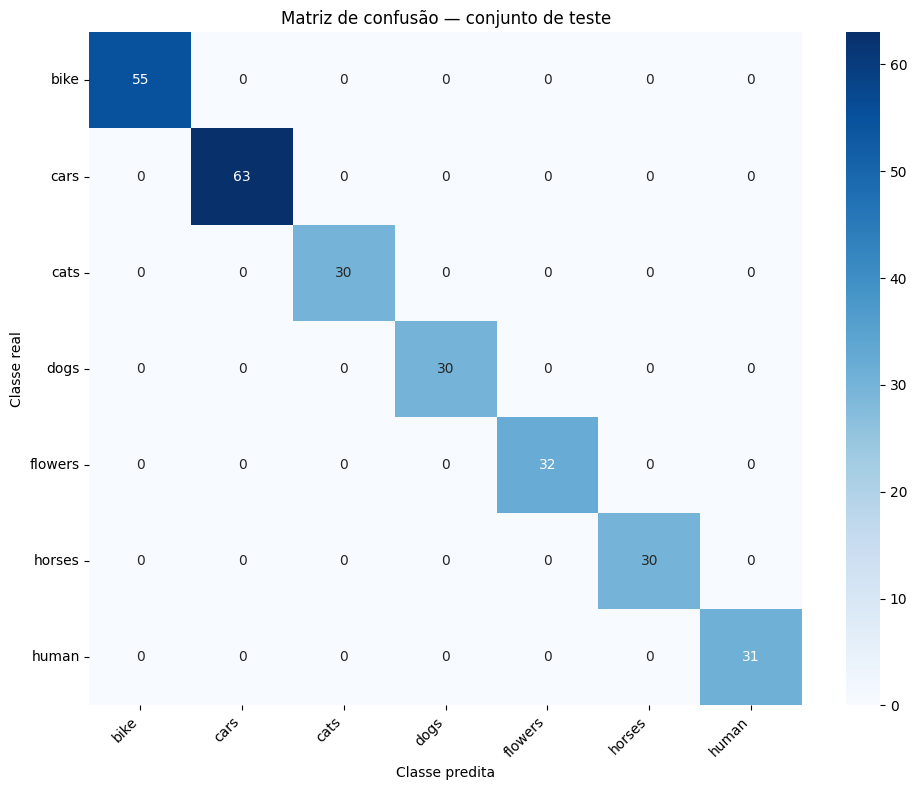

,Classe,Imagens no teste,Acertos,Accuracy (%)
0,bike,55,55,100.0
1,cars,63,63,100.0
2,cats,30,30,100.0
3,dogs,30,30,100.0
4,flowers,32,32,100.0
5,horses,30,30,100.0
6,human,31,31,100.0


In [8]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import seaborn as sns

y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

global_accuracy = accuracy_score(y_true, y_pred)

print(f"Accuracy global no teste: {global_accuracy:.4f}")
print(f"Accuracy global no teste: {global_accuracy * 100:.2f}%")

print("\nRelatório por classe:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
))

# Matriz de confusão.
cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Matriz de confusão — conjunto de teste")
plt.xlabel("Classe predita")
plt.ylabel("Classe real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Accuracy individual: acertos / total de exemplos reais da classe.
class_accuracy = []

for i, name in enumerate(class_names):
    class_indices = [
        j for j, label in enumerate(y_true) if label == i
    ]
    correct = sum(y_pred[j] == i for j in class_indices)
    total_class = len(class_indices)

    acc = correct / total_class if total_class else 0.0

    class_accuracy.append({
        "Classe": name,
        "Imagens no teste": total_class,
        "Acertos": correct,
        "Accuracy (%)": round(acc * 100, 2)
    })

accuracy_df = pd.DataFrame(class_accuracy)
display(accuracy_df)

In [9]:
# Salva os pesos do modelo treinado.
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "seed": SEED
}, "/content/resnet50_transfer_learning.pth")

# Salva as métricas por classe.
accuracy_df.to_csv(
    "/content/accuracy_por_classe.csv",
    index=False
)

# Salva o histórico de treinamento.
pd.DataFrame(history).to_csv(
    "/content/historico_treinamento.csv",
    index_label="epoca"
)

print("Arquivos salvos em /content/")

Arquivos salvos em /content/
